#Tarefa Avaliativa 3

*   Disciplina: Física com Python 1 (2026.2) — CBPF
*   Autor: Guilherme Rodrigues Bento
*   Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

##Parte 1

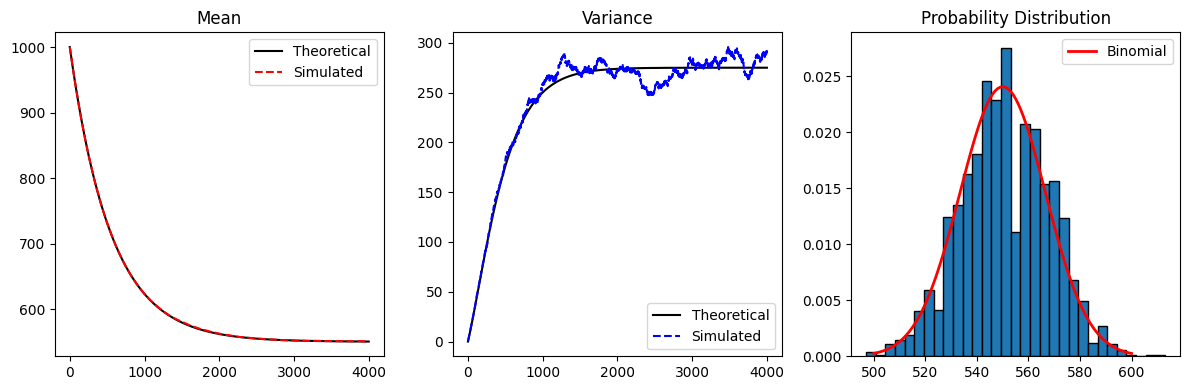

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# -------------------- 1. Simulating the Ehrenfest Gas --------------------

Na_0, Nb_0 = 1000, 100  # Number of particles in A and B
N = Na_0 + Nb_0         # Total number of particles
T = 4000                # Number of steps
S = 2000                # Number of simulations
t = np.arange(T)

# Theoretical Results
mean_teo = (N/2) + ((1 - 2/N)**t) * (Na_0 - N/2)
var_teo = (N/4) + ((1 - 4/N)**t) * (Na_0**2 + (N/4)*(N - 4*Na_0 - 1)) - ((1 - 2/N)**(2*t)) * ((Na_0 - N/2)**2)

# Simulating Results
Na_sim = np.zeros((S, T))
for m in range(S):
    Na = Na_0
    for step in range(T):
        Na_sim[m, step] = Na
        decision = np.random.choice([-1, 1], p=[Na/N, 1 - Na/N])
        Na += decision

mean_sim = np.mean(Na_sim, axis=0)
var_sim = np.var(Na_sim, axis=0)

# -------------------- 2. Plotting Graphs --------------------

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].plot(t, mean_teo, 'k-', label='Theoretical')
ax[0].plot(t, mean_sim, 'r--', label='Simulated')
ax[0].set_title('Mean')
ax[0].legend()

ax[1].plot(t, var_teo, 'k-', label='Theoretical')
ax[1].plot(t, var_sim, 'b--', label='Simulated')
ax[1].set_title('Variance')
ax[1].legend()

ax[2].hist(Na_sim[:, -1], bins='auto', density=True, edgecolor='black')
k = np.arange(500, 600 + 1)
ax[2].plot(k, binom.pmf(k, N, 0.5), 'r-', lw=2, label='Binomial')
ax[2].set_title('Probability Distribution')
ax[2].legend()

plt.tight_layout()
plt.show()

- **Mean (left):** Mathematically, the simulated curve overlaps almost perfectly with the theoretical one. Physically, this indicates that over time particles have no preference for being in compartment A or B, with the equiprobable state ($N/2$) being the equilibrium state of the system.

- **Probability Distribution (right):** In the equilibrium state, the system follows a stationary binomial distribution that does not change over time. Since $N_A$ is the sum of $N$ independent and identically distributed random variables, the Central Limit Theorem (CLT) guarantees that for large $N$ this distribution approaches a Gaussian, which is corroborated by the simulation.

- **Variance (center):** Initially, it starts at zero, indicating a deterministic initial condition where the number of particles in compartment A is known with certainty. Over time, its value grows as the probability distribution broadens from a sharp peak into a gaussian distribution. For long times, the variance tends to a constant, characterizing the stationary equilibrium state. The fluctuations observed in the simulation arise from the finite size of the ensemble used.

##Parte 2

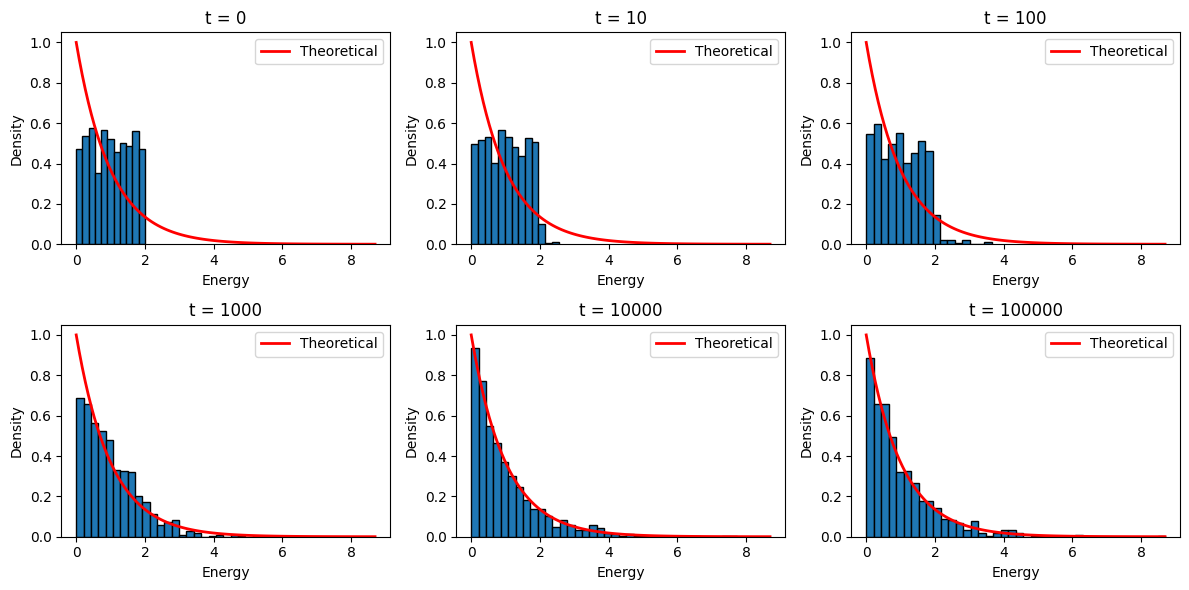

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt

# -------------------- 1. Simulating the Mechanism --------------------

# Initializing

N = 10**3 # Number of particles
Energies = np.random.uniform(0, 2, size = N) # Each particle gets a random value of energy
t = 10**5
times = [0, 10, 10**2, 10**3, 10**4, 10**5]
distribution = []
mean_energies = []
betas = []


# Simulating

j = 0

for i in range(t + 1):
  if i == times[j]:
    distribution.append(Energies.copy())
    mean_energies.append(np.mean(Energies))
    betas.append(1/np.mean(Energies))
    j += 1

  choice1 = np.random.randint(0, N)
  choice2 = np.random.randint(0, N)
  while choice1 == choice2:
    choice2 = np.random.randint(0, N)

  e = np.random.uniform(0, 1)
  Delta = (1 - e)*Energies[choice1] - e*Energies[choice2]
  Energies[choice1] = Energies[choice1] - Delta
  Energies[choice2] = Energies[choice2] + Delta

# -------------------- 2. Plotting Graphs --------------------

fig, ax = plt.subplots(2, 3, figsize=(12, 6))
ax = ax.flatten()  # Transforma o grid 2x3 em uma lista de 6 eixos

w = np.linspace(0, np.max(Energies), 100)

for x in range(6):
  function = betas[x] * np.exp(-betas[x] * w)
  ax[x].hist(distribution[x], bins='auto', density=True, edgecolor='black')
  ax[x].plot(w, function, 'r-', lw=2, label='Theoretical')
  ax[x].set_xlabel('Energy')
  ax[x].set_ylabel('Density')
  ax[x].set_title(f't = {times[x]}')
  ax[x].legend()

plt.tight_layout()
plt.show()

1. **Evolution of the distribution:** The distribution starts uniform, and over time the collisions redistribute the energies. In the end, a few particles reach energies higher than the initial limit, while the majority concentrate close to zero.

2. **Convergence to equilibrium:** For long times, the histogram converges to the theoretical Boltzmann-Gibbs curve, confirming that the system relaxes to a stationary state of thermal equilibrium.

3. **Energy conservation:** According to the update rule, $w_i' + w_j' = (w_i - \Delta w) + (w_j + \Delta w) = w_i + w_j$. Therefore, energy is conserved in the collisions.

4. **Non-negative energy condition:** Physically, this condition represents the impossibility of negative kinetic energy, which would restrict such occurrences in the simulation. However, it is not actually needed here because the energy exchange rules already prevent any energy value from becoming negative. Thus, the non-negative energy condition is not strictly necessary in this simulation.

##Parte 3

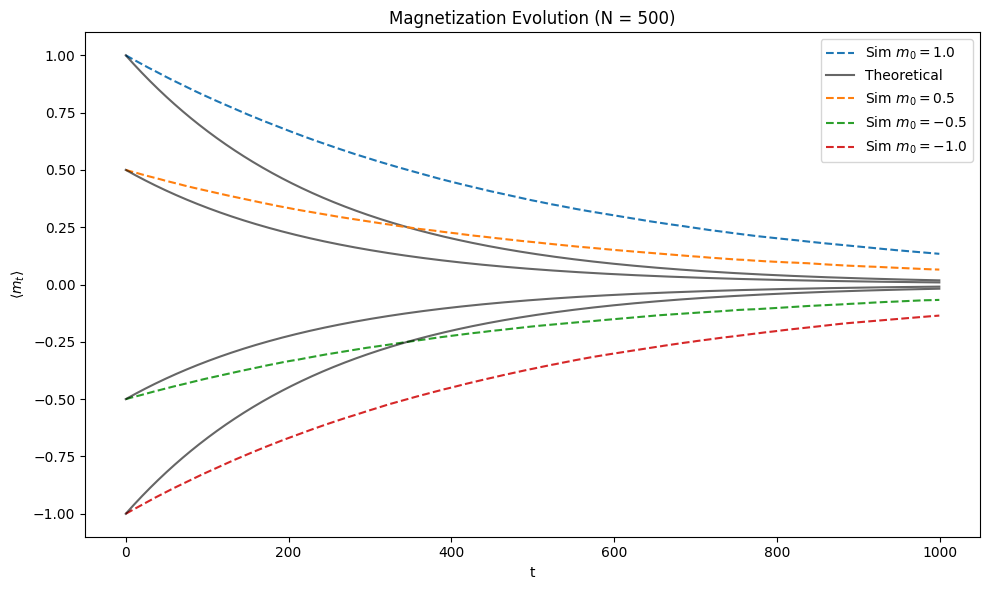

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt

# -------------------- 1. Simulating --------------------

# Creating the lattices

def create_lattice(N, m0):
    n_up = int(round(N * (1 + m0) / 2))
    n_down = N - n_up
    lattice = np.array([1] * n_up + [-1] * n_down)
    np.random.shuffle(lattice)
    return lattice

# Defining some values

m0 = [1.0, 0.5, -0.5, -1.0] # Initial values of magnetization
N = [5, 50, 500] # Number of particles in the lattice
T = 1000 # Number of steps made
S = 500 # Number of simulations
t = np.arange(T)

# Simulating the magnetization with N = 500

m = []

for m0_values in m0:
  m_hist = np.zeros((S, T))
  for i in range(S):
    lattice = create_lattice(N[2], m0_values)
    for j in range(T):
      m_hist[i, j] = np.mean(lattice)
      site = np.random.randint(0, N[2])
      lattice[site] = np.random.choice([-1, 1])
  m_mean_sim = np.mean(m_hist, axis=0)
  m.append(m_mean_sim)

# -------------------- 2. Plotting Graphs --------------------

fig, ax = plt.subplots(figsize=(10, 6))

for i in range(4):
  m_teo = m0[i] * (1 - 2/N[2])**t
  ax.plot(t, m[i], '--', label=f'Sim $m_0 = {m0[i]}$')
  ax.plot(t, m_teo, 'k-', alpha=0.6, label='Theoretical' if i == 0 else "")

ax.set_title(f'Magnetization Evolution (N = {N[2]})')
ax.set_xlabel('t')
ax.set_ylabel('$\\langle m_t \\rangle$')
ax.legend()

plt.tight_layout()
plt.show()

From the simulation, we can clearly see that the theoretical results decay faster than what the simulation indicates.

The explanation for this is that the implementation rule in Section 3 is not the same as the one presented in Section 4. In the former, there is a 50% chance of the spin being flipped, whereas in the latter, there is a 100% chance of it being flipped.

By the rules of Section 3, we have the following cases:

- $M_t + 2$, with probability $P_+ = \frac{1}{2}\left(\frac{N - M_t}{2N}\right) = \frac{N - M_t}{4N}$
- $M_t - 2$, with probability $P_- = \frac{1}{2}\left(\frac{N + M_t}{2N}\right) = \frac{N + M_t}{4N}$
- $M_t$, with probability $P_0 = \frac{1}{2}$

Therefore, the expected value is:

$$\langle M_{t+1} \rangle = (M_t + 2)\frac{N - M_t}{4N} + (M_t - 2)\frac{N + M_t}{4N} + M_t \cdot \frac{1}{2}$$

$$\langle M_{t+1} \rangle = \frac{2NM_t - 4M_t}{4N} + \frac{M_t}{2} = M_t\left(1 - \frac{1}{N}\right)$$

Which results in:

$$\langle m_t \rangle = m_0\left(1 - \frac{1}{N}\right)^t$$

The code below fixes the theoretical value.

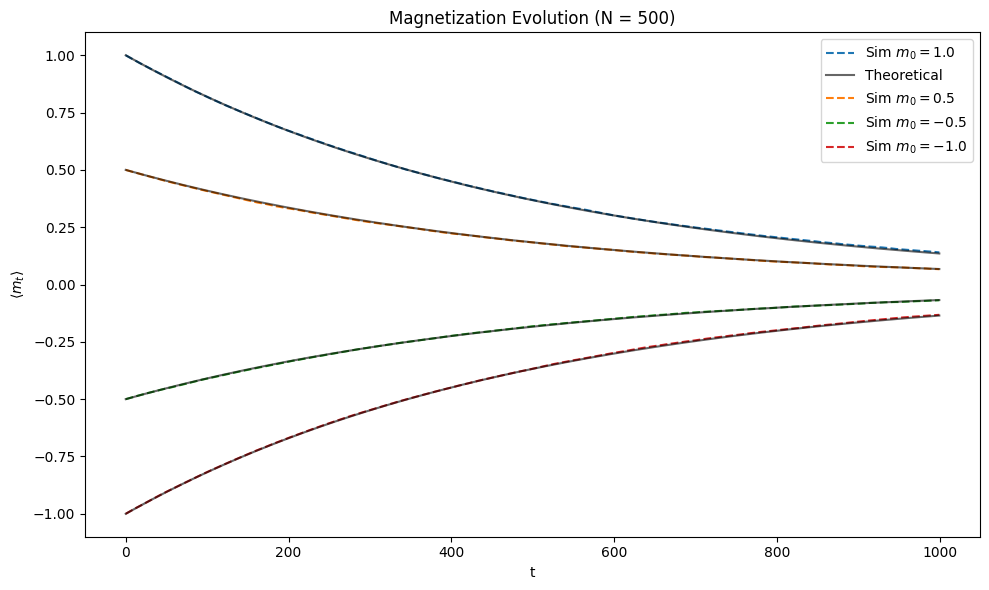

In [ ]:
# -------------------- 0. Importing Packages --------------------

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# -------------------- 1. Functions & Parameters --------------------

def create_lattice(N, m0):
    n_up = int(round(N * (1 + m0) / 2))
    n_down = N - n_up
    lattice = np.array([1] * n_up + [-1] * n_down)
    np.random.shuffle(lattice)
    return lattice

m0_list = [1.0, 0.5, -0.5, -1.0] # Initial values of magnetization
N_list = [5, 50, 500]            # Number of particles in the lattice
T = 1000                         # Number of steps
S = 500                          # Number of simulations (ensemble)
t = np.arange(T)

# -------------------- 2. Effect of m0 (N = 500) --------------------

m = []

for m0_val in m0_list:
    m_hist = np.zeros((S, T))
    for i in range(S):
        lattice = create_lattice(N_list[2], m0_val)
        for j in range(T):
            m_hist[i, j] = np.mean(lattice)
            site = np.random.randint(0, N_list[2])
            lattice[site] = np.random.choice([-1, 1])
    m.append(np.mean(m_hist, axis=0))

fig, ax = plt.subplots(figsize=(10, 6))

for i in range(len(m0_list)):
  m_teo = m0_list[i] * (1 - 1/N_list[2])**t # --> CORRECTION: It is 1/N and not 2/N
  ax.plot(t, m[i], '--', label=f'Sim $m_0 = {m0_list[i]}$')
  ax.plot(t, m_teo, 'k-', alpha=0.6, label='Theoretical' if i == 0 else "")

ax.set_title(f'Magnetization Evolution (N = {N_list[2]})')
ax.set_xlabel('t')
ax.set_ylabel('$\\langle m_t \\rangle$')
ax.legend()

plt.tight_layout()
plt.show()

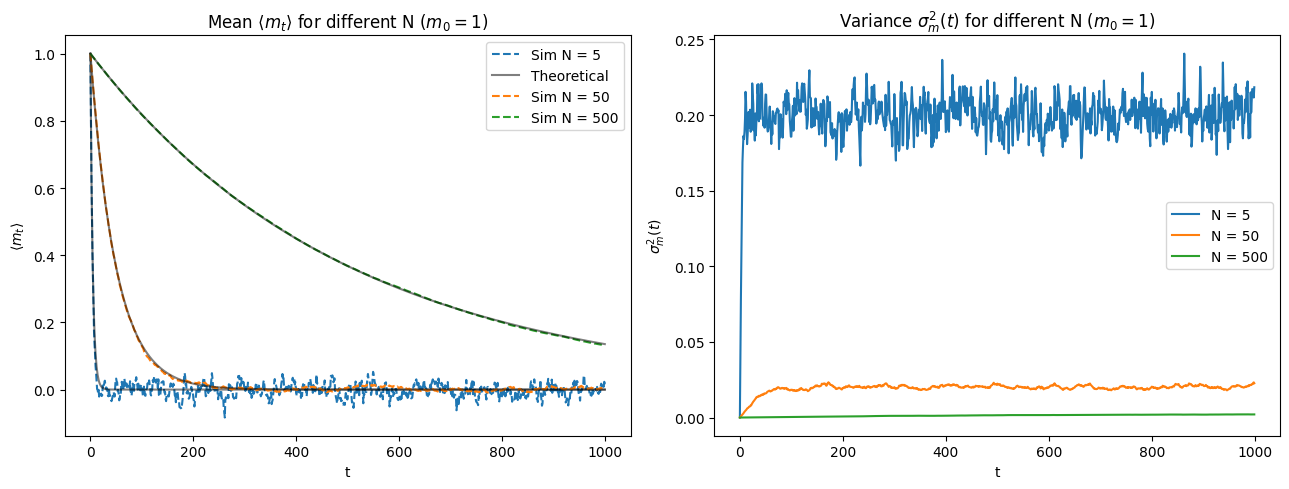

In [ ]:
# -------------------- 3. Effect of N: Mean and Variance (m0 = 1.0) --------------------

m_mean_N = []
m_var_N = []

for N_val in N_list:
    m_hist = np.zeros((S, T))
    for i in range(S):
        lattice = create_lattice(N_val, 1.0)
        for j in range(T):
            m_hist[i, j] = np.mean(lattice)
            site = np.random.randint(0, N_val)
            lattice[site] = np.random.choice([-1, 1])
    m_mean_N.append(np.mean(m_hist, axis=0))
    m_var_N.append(np.var(m_hist, axis=0))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for i in range(len(N_list)):
    m_teo = 1.0 * (1 - 1 / N_list[i])**t # --> Correction: It is 1/N and not 2/N
    ax[0].plot(t, m_mean_N[i], '--', label=f'Sim N = {N_list[i]}')
    ax[0].plot(t, m_teo, 'k-', alpha=0.5, label='Theoretical' if i == 0 else "")
    ax[1].plot(t, m_var_N[i], label=f'N = {N_list[i]}')

ax[0].set_title('Mean $\\langle m_t \\rangle$ for different N ($m_0 = 1$)')
ax[0].set_xlabel('t')
ax[0].set_ylabel('$\\langle m_t \\rangle$')
ax[0].legend()

ax[1].set_title('Variance $\\sigma_m^2(t)$ for different N ($m_0 = 1$)')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\sigma_m^2(t)$')
ax[1].legend()

plt.tight_layout()
plt.show()

1. **Evolution of the average magnetization:** Regardless of the initial magnetization condition, its average value decays exponentially toward zero over time. Physically, we can understand this result by noting that there is no mechanism favoring either spin direction. Therefore, in the long run, the spins are expected to cancel out.

2. **Comparison:** The simulation reproduces the analytically predicted exponential decay. The main difference lies in the statistical fluctuations around the theoretical curve. For the average value, the larger the $N$, the slower the relaxation time. On the other hand, the larger the $N$, the closer the system gets to the theoretically predicted behavior. These two results highlight the relevance of the system size to the behavior of the data.

3. **Fluctuations (Variance):** For all three system sizes used, the variance starts at zero, grows during the transient regime, and saturates at a constant value in equilibrium. However, we clearly see that the smaller the system, the larger the fluctuations.

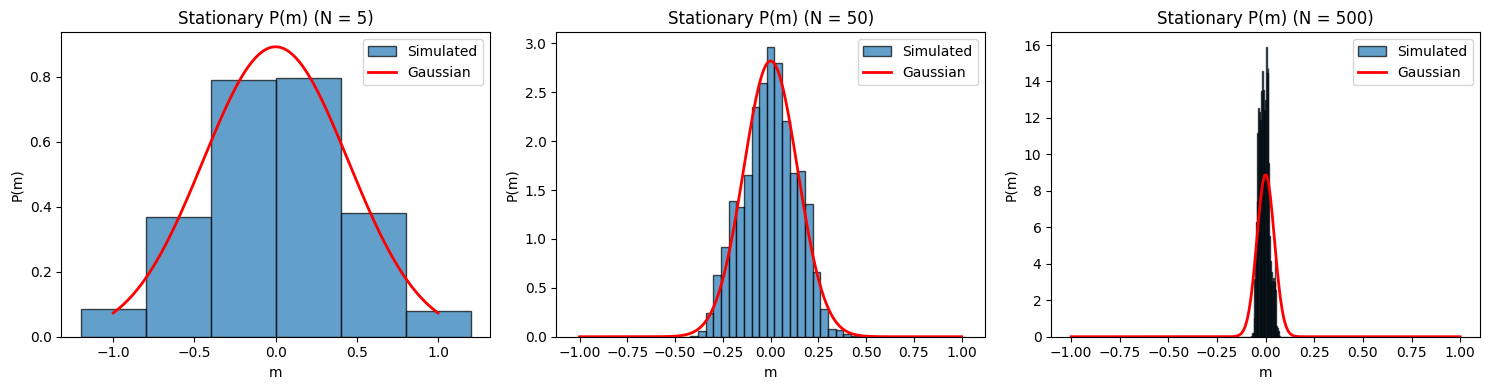

In [ ]:
# -------------------- 4. Stationary Distribution P(m) --------------------

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, N_val in enumerate(N_list):
    transient = 15000
    T_long = 20000
    lattice = create_lattice(N_val, 1.0)
    m_long = np.zeros(T_long)

    for j in range(T_long):
        m_long[j] = np.mean(lattice)
        site = np.random.randint(0, N_val)
        lattice[site] = np.random.choice([-1, 1])

    m_stat = m_long[transient:]  # Descarta o transiente

    bins = np.linspace(-1 - 1/N_val, 1 + 1/N_val, N_val + 2)
    ax[i].hist(m_stat, bins=bins, density=True, alpha=0.7, edgecolor='black', label='Simulated')
    x = np.linspace(-1, 1, 200)
    ax[i].plot(x, norm.pdf(x, 0, np.sqrt(1 / N_val)), 'r-', lw=2, label='Gaussian')
    ax[i].set_title(f'Stationary P(m) (N = {N_val})')
    ax[i].set_xlabel('m')
    ax[i].set_ylabel('P(m)')
    ax[i].legend()

plt.tight_layout()
plt.show()

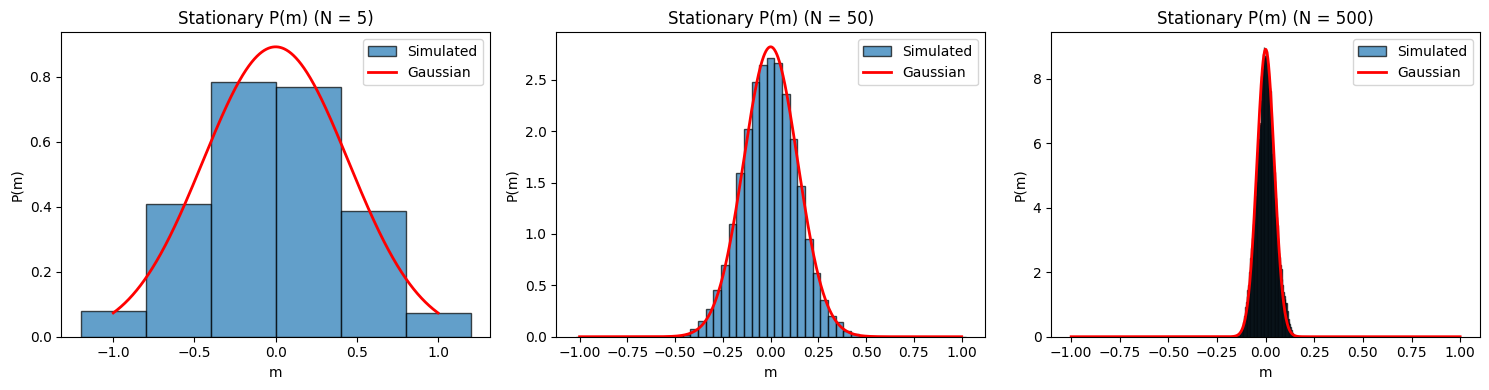

In [ ]:
# -------------------- 4. Stationary Distribution P(m) --------------------

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, N_val in enumerate(N_list):
    transient = 200 * N_val
    T_long = transient + max(50000, 500 * N_val)
    lattice = create_lattice(N_val, 1.0)
    m_long = np.zeros(T_long)

    for j in range(T_long):
        m_long[j] = np.mean(lattice)
        site = np.random.randint(0, N_val)
        lattice[site] = np.random.choice([-1, 1])

    m_stat = m_long[transient:]  # Discard the transient

    bins = np.linspace(-1 - 1/N_val, 1 + 1/N_val, N_val + 2)
    ax[i].hist(m_stat, bins=bins, density=True, alpha=0.7, edgecolor='black', label='Simulated')
    x = np.linspace(-1, 1, 1000)
    ax[i].plot(x, norm.pdf(x, 0, np.sqrt(1 / N_val)), 'r-', lw=2, label='Gaussian')
    ax[i].set_title(f'Stationary P(m) (N = {N_val})')
    ax[i].set_xlabel('m')
    ax[i].set_ylabel('P(m)')
    ax[i].legend()

plt.tight_layout()
plt.show()

4. **Distribuição de Probabilidades**: No estado estacionário, os $N$ spins são variáveis independentes e identicamente distribuídas (assumindo $+1$ ou $-1$ com igual probabilidade). Pelo TCL, conforme $N$ aumenta, essa distribuição tende a uma gaussiana centrada em zero. Já a LGN explica o estreitamento progressivo da curva: à medida que $N$ cresce, as flutuações diminuem e $m$ converge cada vez mais para o valor médio esperado ($\langle m \rangle = 0$).